## Cover designs: the iris

Two cover designs built entirely from recorded data, with no drawing or manual layout. Each point is **one recorded neuron, shown as its own two-photon max-projection image**: the tiles from `cover_art.ipynb` (41 × 41 px crop around the ROI, inverted, isolated from neighbors). Neurons are arranged as an iris:

- **Pupil edge: Vip.** Where light enters the eye; Vip cells carry much of the novelty signal.
- **Middle: Excitatory.**
- **Outer rim: Sst.** The stabilizing boundary; most Sst cells prefer familiar stimuli.

| | Design A: functional map | Design B: preference pies |
|---|---|---|
| Angle around the eye | each cell's position around the ring of the UMAP functional map | that cell type's pie chart from the graphical abstract (one sector per cluster, width = % of cells) |
| Color | functional cluster (graphical-abstract v1 palette) | the cluster's preferred experience level (Familiar / Novel / Novel + / none) |
| Cells | 2,845 (cluster 1 and far UMAP outliers excluded) | 3,762 (all 12 clusters) |

Both come in a **dark** version (cells glow on black, like fluorescence) and a **light** version (cells on white with a dark pupil).

**Neuron cover rules applied:** 9 × 11.5 in at 300 dpi (2700 × 3450 px; final trim 8⅜ × 10⅞ in, iris kept inside it); TIF with LZW compression; top of the page left clear for the masthead; **no red and green together** (Design A: cluster 6 recolored from green to brown; Design B: the pies' feature ring, whose "images" color is green, is left out).

**Outputs** (`cover_art/designs/`): `cover_iris_umap_{dark,light}.tif`, `cover_iris_pies_{dark,light}.tif`, small `_preview.jpg` versions, and `_layout.csv` files listing which neuron is where.
Code: `cover_layout.py` (arrangement), `cover_render.py` (compositing), `make_cover.py` (file output).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import visual_behavior.visualization.utils as utils
import visual_behavior.data_access.loading as loading
from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

import cover_layout as L   # same folder as this notebook
import make_cover

%load_ext autoreload
%autoreload 2
%matplotlib inline

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/xarray/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/marinag/Documents/Code/visual_behavior_analysis/visual_behavior/data_access/from_lims.py:37: UserWarning: failed to set up LIMS/mtrain 

In [2]:
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'cover_art')
tile_dir = os.path.join(save_dir, 'cell_tiles_isolated')        # made by cover_art.ipynb
design_dir = os.path.join(save_dir, 'designs')
os.makedirs(design_dir, exist_ok=True)
tile_manifest = os.path.join(tile_dir, 'tile_manifest_crisp.csv')

## Data loading (same files as figure_5_main / graphical_abstract_v2)

In [3]:
glm_results_dir = loading.get_glm_results_dir()
data_dir = loading.get_clustering_results_dir()

feature_matrix = pd.read_hdf(os.path.join(data_dir, 'clustering_feature_matrix.h5'), key='df')
feature_matrix = feature_matrix.rename(columns={'all-images': 'images', 'behavioral': 'behavior'})
n_clusters = 14
cluster_meta = pd.read_hdf(os.path.join(data_dir, f'cluster_metadata_{n_clusters}_clusters.h5'), key='df')
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'across_session_normalized_platform_results_pivoted.h5'), key='df')
umap_df = pd.read_hdf(os.path.join(data_dir, 'umap_results_df.h5'), key='df')

# one table of clustered cells: UMAP position, cluster, cell type (read by cover_layout.load_cells)
cluster_csv = os.path.join(design_dir, 'umap_cells.csv')
umap_df[['x', 'y']].join(cluster_meta[['cluster_id', 'cell_type']]).to_csv(cluster_csv)
print(len(cluster_meta), 'clustered cells;', len(pd.read_csv(tile_manifest)), 'crisp tiles')

3901 clustered cells; 3762 crisp tiles


### Cluster preferences, pie order and pie fractions (Design B)

Copied unchanged from `graphical_abstract_v2.ipynb` so the iris matches the graphical-abstract pies exactly.
Preferred experience = Familiar vs mean(Novel, Novel +) on the cluster's dominant feature (novelty index ≥ 0.15 → the larger of Novel / Novel +; ≤ −0.15 → Familiar; otherwise, or if peak coding < 0.1, no preference).
Pie order = grouped by preferred experience (Familiar, Novel, Novel +, none), then preferred feature, then dendrogram order (`PIE_ORDER = 'experience'`). Fractions = % of each cell type's cells in each cluster (full population).

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram

EXP_SEL_MIN = 0.15
EXP_SCORE_MIN = 0.1

features = processing.get_features_for_clustering()           # ['all-images', 'omissions', 'task', 'behavioral']
feature_cols = plotting.get_feature_colors_with_gray()         # [gray] + one color per feature
exp_levels, exp_cols = utils.get_experience_levels(), utils.get_experience_level_colors()
FAM, NOV, NOVP = exp_levels

cm = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
rp = (results_pivoted if 'cluster_id' in results_pivoted.columns
      else results_pivoted.merge(cluster_meta[['cluster_id']], on='cell_specimen_id'))
lvl_means = rp.groupby(['cluster_id', 'experience_level'])[features].mean()

rows = []
for c in cm.index:
    feat = cm.loc[c, 'dominant_feature']
    v = lvl_means.loc[c][feat]
    fam, nov = v[FAM], (v[NOV] + v[NOVP]) / 2
    idx = (nov - fam) / (nov + fam) if (nov + fam) > 0 else 0.0
    pref = (NOV if v[NOV] >= v[NOVP] else NOVP) if idx >= EXP_SEL_MIN else (FAM if idx <= -EXP_SEL_MIN else None)
    noncoding = max(fam, v[NOV], v[NOVP]) < EXP_SCORE_MIN
    if noncoding:
        pref = None
    rows.append(dict(cluster_id=c, dominant_feature=feat, Familiar=fam, Novel=v[NOV], **{'Novel +': v[NOVP]},
                     novelty_index=idx, preferred_experience=pref,
                     feature_color=feature_cols[0] if noncoding else feature_cols[1 + features.index(feat)],
                     exp_color=exp_cols[exp_levels.index(pref)] if pref is not None else None))
cluster_info = pd.DataFrame(rows).set_index('cluster_id').sort_index()

# dendrogram of cluster-mean coding scores (Euclidean, average linkage) -- identical to Fig 5
cent = feature_matrix.loc[cluster_meta.index].groupby(cluster_meta.cluster_id.values).mean()
dendro_Z = linkage(cent.values, method='average', metric='euclidean')
dendro_labels = list(cent.index)
leaf_order = list(dendrogram(dendro_Z, labels=dendro_labels, no_plot=True)['ivl'])[::-1]
cluster_info['dendro_rank'] = [leaf_order.index(c) for c in cluster_info.index]

# fraction of each cell type's cells in each cluster (full population, incl. cluster 1)
cell_types = utils.get_cell_types()
pie_fracs = (cluster_meta.groupby(['cell_type', 'cluster_id']).size()
             .unstack(fill_value=0).reindex(index=cell_types, columns=leaf_order, fill_value=0))
pie_fracs = pie_fracs.div(pie_fracs.sum(axis=1), axis=0)

# pie wedge order, as graphical_abstract_v2 with PIE_ORDER = 'experience'
exp_rank = {lvl: i for i, lvl in enumerate(exp_levels)}
feat_rank = {f: i for i, f in enumerate(features)}
pie_order = sorted(cluster_info.index, key=lambda c: (
    exp_rank.get(cluster_info.loc[c, 'preferred_experience'], len(exp_levels)),            # no preference last
    len(features) if cluster_info.loc[c, 'feature_color'] == feature_cols[0]                 # non-coding last
    else feat_rank[cluster_info.loc[c, 'dominant_feature']],
    cluster_info.loc[c, 'dendro_rank']))
preferred_experience = cluster_info.preferred_experience.to_dict()

print('pie order (clockwise from 12 o\'clock):', pie_order)
print(cluster_info[['dominant_feature', 'novelty_index', 'preferred_experience']].round(2).to_string())
print('\n% of cells per cluster, per cell type:')
print((100 * pie_fracs[pie_order]).round(1).to_string())

pie order (clockwise from 12 o'clock): [7, 6, 4, 8, 10, 3, 2, 11, 5, 9, 12, 1]
           dominant_feature  novelty_index preferred_experience
cluster_id                                                     
1                all-images          -0.40                 None
2                all-images           0.90                Novel
3                all-images           0.81                Novel
4                all-images          -0.87             Familiar
5                all-images           0.90              Novel +
6                all-images          -0.16             Familiar
7                all-images          -0.19             Familiar
8                 omissions          -0.65             Familiar
9                 omissions           0.49              Novel +
10                     task          -0.35             Familiar
11                     task           0.87                Novel
12               behavioral           0.14                 None

% of cells per cluster, 

## Design A: iris of the functional map

**Data.** 2,845 neurons (2,326 excitatory, 336 Vip, 183 Sst) imaged with two-photon calcium imaging in mouse visual cortex during the change-detection task, tracked across familiar, novel and novel+ sessions, and grouped into functional clusters by their coding scores (Figure 5). Each point is that neuron's own max-projection image (~30 µm crop around its ROI), inverted and painted in its cluster's color. Excluded, as in the original UMAP graphical abstract: cluster 1 (non-coding) and the far UMAP outliers. Only tiles passing the sharpness filter are used.

**Organization.**
- **Angle:** the clusters form a ring in UMAP space. Each neuron's angle around the eye is its angle around that ring, rank-ordered within its cell type so the band fills evenly. Neurons next to each other on the iris have similar coding.
- **Radius:** cell type. Vip at the pupil edge, excitatory in the middle, Sst at the rim. Radial position within a band is random.
- **Size:** tiles grow toward the rim, and interneuron tiles are drawn larger so the thin Vip and Sst bands read. Every neuron appears exactly once.

**Meaning.** An eye built from the visual-cortex neurons that process what it sees. Vip cells, which carry much of the novelty signal, sit where light enters. Sst cells, which mostly encode familiar images, form the stabilizing outer boundary. Every band holds many colors: each cell class is functionally diverse, the paper's central finding.

*Note: the UMAP was removed from Figure 5, so this design depends on whether the UMAP stays in the graphical abstract.*

In [5]:
cells_a = L.load_cells(cluster_csv, tile_manifest, drop_clusters=(1,))
cells_a = cells_a[cells_a.x < 16]                          # far UMAP outliers, as in the graphical abstract v1
layout_a = L.umap_iris(cells_a)
paths_a = make_cover.make_design('cover_iris_umap', layout_a, tile_dir, design_dir, pupil_r=310)
print(layout_a.cell_type.value_counts().to_dict())

{'Excitatory': 2326, 'Vip Inhibitory': 336, 'Sst Inhibitory': 183}


## Design B: iris of the preference pies

**Data.** 3,762 neurons (3,174 excitatory, 397 Vip, 191 Sst): every clustered neuron with a crisp tile, in all 12 clusters. As in Design A, each point is the neuron's own max-projection image.

**Organization.**
- **Each band is one cell type's pie chart** from the graphical abstract. Clusters are angular sectors, clockwise from 12 o'clock, in the same order as the pies (grouped by preferred experience level, then preferred feature, then dendrogram order).
- **Sector width** = the percentage of that cell type's neurons in the cluster, so each sector holds that cluster's neurons. The pies' cluster-ID labels are not drawn.
- **Color** = the cluster's preferred experience level, as in the pie wedges: blue = Familiar, red = Novel, purple = Novel +, gray = no preference.
- **Feature ring:** left out, because its "images" color is green and Cell Press asks that red and green not be used together.
- **Bands and sizes:** as in Design A, with Vip at the pupil edge, excitatory in the middle and Sst at the rim.

**Meaning.** Read around the eye, the bands differ. The Sst rim is mostly blue: about three-quarters of Sst neurons are in familiar-preferring clusters, the stable boundary of the circuit. The excitatory and Vip bands are mixed: novelty-preferring clusters (red and purple) hold about 44% of excitatory and 40% of Vip neurons, and Vip has the largest share of cells with no single preference. Color varies within every band: each cell class splits into functionally distinct groups.

In [6]:
cells_b = L.load_cells(cluster_csv, tile_manifest)
layout_b = L.pie_iris(cells_b, pie_fracs, pie_order, preferred_experience)
paths_b = make_cover.make_design('cover_iris_pies', layout_b, tile_dir, design_dir, pupil_r=310)
print(layout_b.cell_type.value_counts().to_dict())

{'Excitatory': 3174, 'Vip Inhibitory': 397, 'Sst Inhibitory': 191}


## Checks

In [7]:
# every neuron used once; nothing outside Neuron's trim (8 3/8 x 10 7/8 in centred in 9 x 11.5 in = 94 px per edge)
for name, lay in [('A umap', layout_a), ('B pies', layout_b)]:
    out = ((lay.X - lay['size'] / 2 < 94) | (lay.X + lay['size'] / 2 > L.W - 94) |
           (lay.Y - lay['size'] / 2 < L.TOP) | (lay.Y + lay['size'] / 2 > L.H - 94)).sum()
    print(f'{name}: {len(lay)} tiles, {lay.cell_specimen_id.nunique()} unique neurons, {out} outside trim / in masthead')

# Design B: share of each band's neurons per experience preference (tiles drawn) vs the pies (full population)
pref_of = lambda s: s.map(preferred_experience).fillna('none')
drawn = pd.crosstab(layout_b.cell_type, pref_of(layout_b.cluster_id), normalize='index')
pies = pd.crosstab(cluster_meta.cell_type, pref_of(cluster_meta.cluster_id), normalize='index')
print('\n% per preferred experience -- drawn tiles / pie charts')
print((100 * drawn).round(1).astype(str) + ' / ' + (100 * pies).round(1).astype(str))

A umap: 2845 tiles, 2845 unique neurons, 0 outside trim / in masthead
B pies: 3762 tiles, 3762 unique neurons, 0 outside trim / in masthead

% per preferred experience -- drawn tiles / pie charts
cluster_id         Familiar        Novel      Novel +         none
cell_type                                                         
Excitatory      29.6 / 29.9  34.4 / 34.1  10.3 / 10.3  25.6 / 25.8
Sst Inhibitory  77.0 / 76.8    9.4 / 9.8    5.8 / 5.7    7.9 / 7.7
Vip Inhibitory  26.7 / 26.4  22.7 / 22.5  17.6 / 17.1  33.0 / 34.0


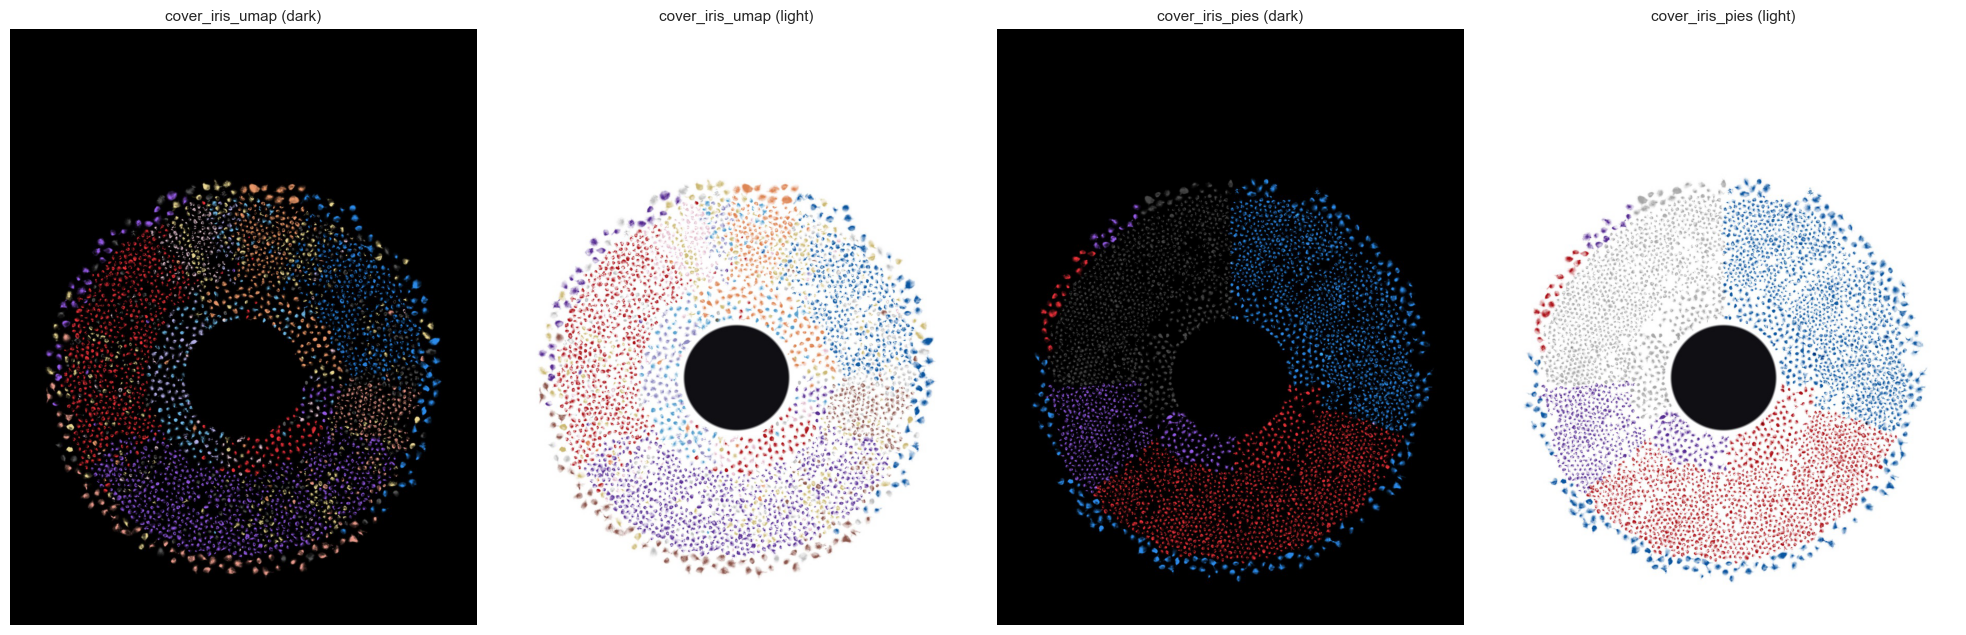

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(20, 7))
for a, (name, mode) in zip(ax, [(n, m) for n in ['cover_iris_umap', 'cover_iris_pies'] for m in ['dark', 'light']]):
    a.imshow(plt.imread(os.path.join(design_dir, f'{name}_{mode}_preview.jpg')))
    a.set_title(f'{name} ({mode})', fontsize=11); a.axis('off')
fig.tight_layout()